<a href="https://colab.research.google.com/github/Salvatorecoscab/ALUbb/blob/main/hk_p3sam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hunyuan3D-Part (P3-SAM): separar `hk_20cm.glb` en partes

**Antes de empezar:** menú **Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4** → Guardar.
Si ya habías corrido la versión anterior: **Entorno de ejecución → Desconectar y borrar el entorno** para empezar limpio.

Ejecuta las celdas **en orden** (Shift+Enter).

P3-SAM corre en un entorno aparte con **Python 3.12 + PyTorch 2.5.1 (CUDA 12.4)**, porque el Python de Colab es más nuevo
y sus librerías (`spconv`/`cumm`) intentan compilarse y fallan.

Resultado: `hk_partes.zip` con
- `hk_partes_color.glb`: el modelo con cada parte en un color (para revisarlo),
- `hk_face_ids.npy`: a qué parte pertenece cada triángulo del modelo original (para cortarlo en piezas imprimibles),
- `partes/parte_XX.stl`: cada parte como superficie (abierta: sirve para ver, **no** para imprimir directo).

## 1. Revisar la GPU

In [1]:
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv

name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07


## 2. Crear el entorno Python 3.12 e instalar todo (≈5 min)

In [2]:
import os
if not os.path.exists('/content/Hunyuan3D-Part'):
    !git clone -q --depth 1 https://github.com/Tencent-Hunyuan/Hunyuan3D-Part /content/Hunyuan3D-Part

!pip -q install uv
!rm -rf /content/py312
!uv venv -q --python 3.12 /content/py312
PY = '/content/py312/bin/python'
SCATTER = 'https://data.pyg.org/whl/torch-2.5.0%2Bcu124/torch_scatter-2.1.2%2Bpt25cu124-cp312-cp312-linux_x86_64.whl'
# todo en UN solo comando, con torch fijo en 2.5.1 para que nada lo reemplace
PKGS = f'"torch==2.5.1+cu124" "{SCATTER}" "spconv-cu124==2.3.8" cumm-cu124 "numpy<2.1" scipy scikit-learn addict omegaconf timm fpsample numba trimesh safetensors huggingface_hub fast-simplification tqdm packaging'
!uv pip install -q --python {PY} --index-url https://pypi.org/simple --extra-index-url https://download.pytorch.org/whl/cu124 --index-strategy unsafe-best-match {PKGS}

!{PY} -c "import torch, spconv.pytorch, torch_scatter; print('torch', torch.__version__, '| scatter', torch_scatter.__version__, '| GPU:', torch.cuda.is_available(), torch.cuda.get_device_name(0)); print('Dependencias OK')"

torch 2.5.1+cu124 | scatter 2.1.2+pt25cu124 | GPU: True Tesla T4
Dependencias OK


## 3. Ajuste para la GPU T4
La T4 no soporta *FlashAttention*, así que se desactiva (el modelo funciona igual, solo usa un poco más de memoria).

In [3]:
p = '/content/Hunyuan3D-Part/XPart/partgen/models/sonata/model.py'
s = open(p).read()
s = s.replace("# ckpt[\"config\"]['enable_flash'] = False", "ckpt[\"config\"]['enable_flash'] = False")
open(p, 'w').write(s)
print('FlashAttention desactivado' if "    ckpt[\"config\"]['enable_flash'] = False" in s else 'ADVERTENCIA: no se encontró la línea a cambiar')

FlashAttention desactivado


## 4. Subir el modelo
Selecciona `hk_20cm.glb` (está en tu carpeta `mariposa`).

In [4]:
from google.colab import files
up = files.upload()
MESH = '/content/' + list(up.keys())[0]
print('Archivo:', MESH)

Saving hk_20cm.glb to hk_20cm.glb
Archivo: /content/hk_20cm.glb


## 5. Script de segmentación
(Solo se escribe el archivo; se ejecuta en el paso 6.)

In [8]:
%%writefile /content/seg_hk.py
import os, sys, json, glob, zipfile, argparse
import numpy as np, trimesh
from scipy.spatial import cKDTree

ap = argparse.ArgumentParser()
ap.add_argument('--mesh'); ap.add_argument('--caras', type=int, default=300000)
ap.add_argument('--umbral', type=float, default=0.95); ap.add_argument('--puntos', type=int, default=100000)
ap.add_argument('--prompts', type=int, default=400)
a = ap.parse_args()

os.chdir('/content/Hunyuan3D-Part/P3-SAM/demo')
sys.path.insert(0, '/content/Hunyuan3D-Part/P3-SAM/demo')
sys.argv = ['auto_mask.py']
from auto_mask import AutoMask, set_seed

# modelo original SIN reordenar triángulos (para que las etiquetas coincidan con el GLB)
orig = trimesh.load(a.mesh, force='mesh', process=False)
print('original:', len(orig.faces), 'caras | tamaño', orig.extents.round(3), flush=True)
seg_in = orig.copy(); seg_in.merge_vertices()
if len(seg_in.faces) > a.caras:
    seg_in = seg_in.simplify_quadric_decimation(face_count=a.caras)
print('para segmentar:', len(seg_in.faces), 'caras', flush=True)

auto_mask = AutoMask(None)   # descarga los pesos de HuggingFace la primera vez
set_seed(42)
os.makedirs('/content/res', exist_ok=True)
aabb, face_ids, seg_mesh = auto_mask.predict_aabb(
    seg_in, save_path='/content/res', point_num=a.puntos, prompt_num=a.prompts,
    threshold=a.umbral, post_process=True, save_mid_res=False, show_info=True,
    seed=42, is_parallel=False, clean_mesh_flag=True, prompt_bs=8)
face_ids = np.asarray(face_ids)

# cada triángulo original toma la parte del triángulo segmentado más cercano
_, nn = cKDTree(seg_mesh.triangles_center).query(orig.triangles_center, workers=-1)
ids = face_ids[nn]
if (ids == -1).any() and (ids != -1).any():
    good = ids != -1
    _, j = cKDTree(orig.triangles_center[good]).query(orig.triangles_center[~good], workers=-1)
    ids[~good] = ids[good][j]
np.save('/content/hk_face_ids.npy', ids)

uniq = sorted(set(ids.tolist()))
rng = np.random.default_rng(0)
pal = {u: np.r_[rng.integers(40, 255, 3), 255] for u in uniq}
fc = np.array([pal[i] for i in ids], np.uint8)
np.save('/content/hk_face_colors.npy', fc)
vis = orig.copy(); vis.visual = trimesh.visual.ColorVisuals(vis, face_colors=fc)
vis.export('/content/hk_partes_color.glb')

os.makedirs('/content/partes', exist_ok=True)
for f in glob.glob('/content/partes/*'): os.remove(f)
for k, u in enumerate(uniq):
    sub = orig.submesh([np.where(ids == u)[0]], append=True)
    sub.export(f'/content/partes/parte_{k:02d}.stl')
    print(f'parte_{k:02d}: {(ids==u).sum():>8} caras  tamaño {np.round(sub.extents*1000,1)} mm')

with zipfile.ZipFile('/content/hk_partes.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    z.write('/content/hk_partes_color.glb', 'hk_partes_color.glb')
    z.write('/content/hk_face_ids.npy', 'hk_face_ids.npy')
    for f in sorted(glob.glob('/content/partes/*.stl')): z.write(f, 'partes/' + os.path.basename(f))
print('PARTES:', len(uniq), '| zip:', round(os.path.getsize('/content/hk_partes.zip')/1e6, 1), 'MB')

Overwriting /content/seg_hk.py


## 6. Separar en partes con P3-SAM (≈5–15 min)
- `CARAS_SEG`: el modelo tiene 1.5 millones de triángulos; se simplifica a esta cantidad para la IA y luego las etiquetas se pasan al modelo completo.
- `UMBRAL` (0.90–0.98): **más bajo = menos partes y más grandes**; más alto = más partes pequeñas.
- Si sale *CUDA out of memory*: baja `PUNTOS` a 60000 o `CARAS_SEG` a 150000.

In [11]:
CARAS_SEG = 150_000
UMBRAL    = 0.95
PROMPTS   = 400

!PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True {PY} /content/seg_hk.py --mesh "{MESH}" --caras {CARAS_SEG} --umbral {UMBRAL} --prompts {PROMPTS}

original: 1569814 caras | tamaño [0.173 0.2   0.096]
para segmentar: 150000 caras
Loading checkpoint from HuggingFace: sonata ...
flash attention: False
Model params: 108.46M 108461376
trying to download model from huggingface...
download model from huggingface to: /.cache/p3sam/weights/p3sam/p3sam.safetensors
>>>>>>代码加载mesh 运行时间: 17.1077 秒
点数：91410 面片数：149974
>>>>>>代码获取邻接面片 运行时间: 0.1128 秒
>>>>>>代码处理邻接面片 运行时间: 2.1895 秒
>>>>>>代码采样点云 运行时间: 0.1138 秒
点数：100000 面片数：149974
>>>>>>代码获取特征 运行时间: 3.1310 秒
预处理特征
>>>>>>代码FPS采样提示点 运行时间: 0.2298 秒
采样完成

>>>>>>代码推理 运行时间: 79.8825 秒
prmopt 推理完成
>>>>>>代码根据IOU排序 运行时间: 0.0004 秒

>>>>>>代码NMS 运行时间: 9.3430 秒
NMS完成，mask数量：33
>>>>>>代码过滤只有一个mask的cluster 运行时间: 0.0000 秒
过滤前：33 个cluster，过滤后：23 个cluster
>>>>>>代码再次合并 运行时间: 0.6173 秒
再次合并，合并数量：22
>>>>>>代码计算没有mask的点 运行时间: 0.0199 秒
100 个点没有mask, 占比：0.0010

>>>>>>代码修补遗漏mask 运行时间: 0.4588 秒
修补遗漏mask：22
>>>>>>代码计算点云最终mask 运行时间: 0.0113 秒
最终mask数量：22
>>>>>>代码点云上色 运行时间: 0.0219 秒
>>>>>>代码投影Mesh并统计label 运行时间: 0.5220 秒
生成face_ids完成

## 7. Vista previa

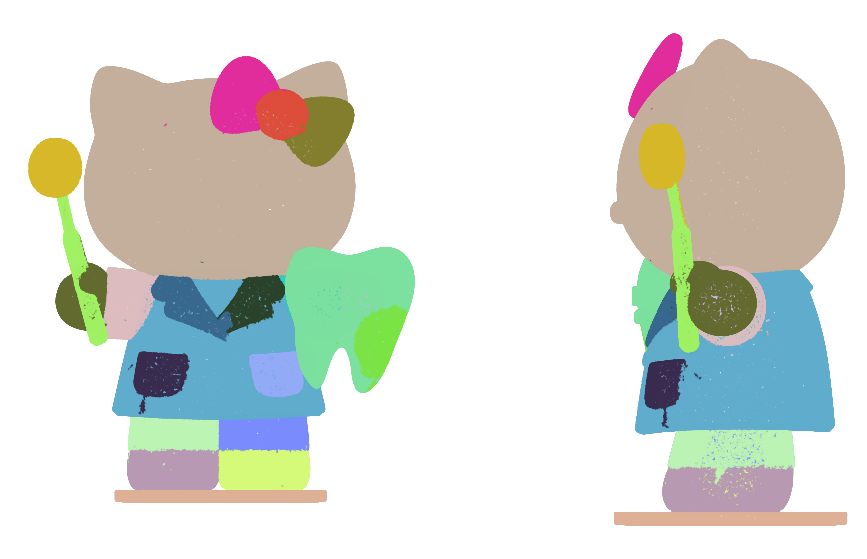

In [12]:
!pip -q install trimesh
import numpy as np, trimesh, matplotlib.pyplot as plt
orig = trimesh.load(MESH, force='mesh', process=False)
fc = np.load('/content/hk_face_colors.npy')
P, fi = trimesh.sample.sample_surface(orig, 400_000, seed=1)
c = fc[fi][:, :3] / 255
fig, ax = plt.subplots(1, 2, figsize=(12, 7))
for a, (h, d, s) in zip(ax, [(0, 2, 1), (2, 0, -1)]):
    o = np.argsort(P[:, d] * s)
    a.scatter(P[o, h] * (1 if s > 0 else -1), P[o, 1], c=c[o], s=0.3); a.set_aspect('equal'); a.axis('off')
plt.show()

## 8. Descargar
Si la división no te gusta, cambia `UMBRAL` en el paso 6 y vuelve a ejecutar los pasos 6–8.

In [13]:
files.download('/content/hk_partes.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>